# Experiment 8: K-Means Clustering on the Digits Dataset
## Aim
Implement and apply K-means clustering to the Digits dataset, experiment with different numbers of clusters, evaluate the results using inertia and silhouette score, and analyze how the choice of K affects clustering quality.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## Load and Preprocess the Digits Dataset

In [2]:
digits=load_digits()
X=digits.data
print(X.shape)
print(np.isnan(X).sum(),'missing values')

X_scaled=StandardScaler().fit_transform(X)

(1797, 64)
0 missing values


## K-Means with Various Numbers of Clusters

In [3]:
k_values=range(2,21)
results=[]
for k in k_values:
    km=KMeans(n_clusters=k,n_init=10,random_state=42)
    labels=km.fit_predict(X_scaled)
    results.append({'K':k,'Inertia':km.inertia_,'Silhouette Score':silhouette_score(X_scaled,labels)})

results_df=pd.DataFrame(results)
results_df

,K,Inertia,Silhouette Score
0,2,100423.843034,0.105638
1,3,93842.482749,0.105287
2,4,89213.968157,0.095386
3,5,85096.054668,0.102298
4,6,81678.466699,0.098789
5,7,77749.327896,0.113494
6,8,74854.159172,0.126590
7,9,72029.725334,0.135985
8,10,69813.559137,0.139377
9,11,67261.847461,0.153194


## Evaluate Using Inertia and Silhouette Score

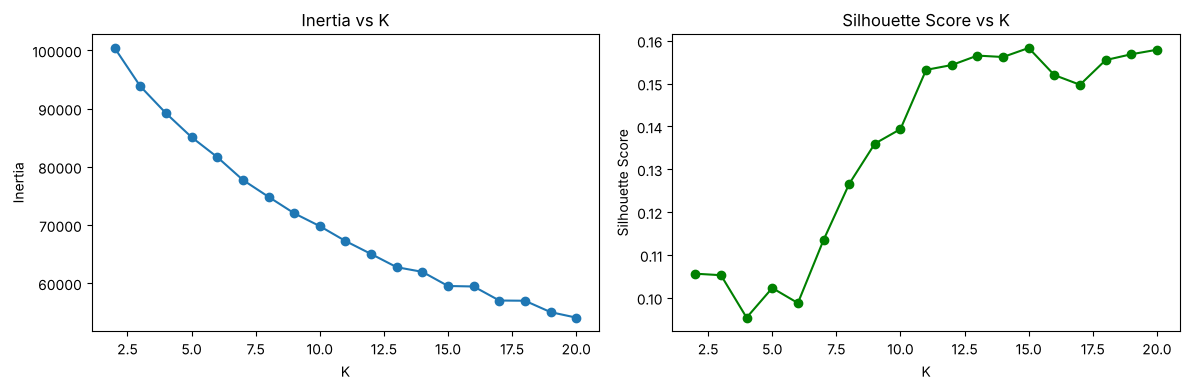

Highest silhouette score: K = 15 -> 0.1583


In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(results_df['K'],results_df['Inertia'],marker='o')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Inertia vs K')

axes[1].plot(results_df['K'],results_df['Silhouette Score'],marker='o',color='green')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score vs K')
plt.tight_layout()
plt.show()

best=results_df.loc[results_df['Silhouette Score'].idxmax()]
print('Highest silhouette score: K =',int(best['K']),'->',round(best['Silhouette Score'],4))

## Analysis
**Inertia** (the sum of squared distances from each point to its cluster centre) falls steadily as K grows, from about 100,400 at K=2 to about 54,100 at K=20. This is guaranteed, because more centres always sit closer to the points, so inertia alone cannot tell us the best K (at K = number of samples it would be zero). The curve bends gently rather than sharply: the drop per extra cluster is large at first (about 6,600 from K=2 to K=3, 4,600 from K=3 to K=4) and shrinks to roughly 2,000-2,500 per step around K=9 to K=12 and below 1,000 for some later steps, so there is no clear elbow and the elbow method points only loosely to a K somewhere around 10-15.

**Silhouette score** (ranging from -1 to 1, higher is better) measures how close each point is to its own cluster compared with the nearest other cluster. Here it is low throughout (between 0.095 and 0.158), which means the clusters overlap and are not well separated in the 64-dimensional pixel space. It is lowest at K=4 (0.095), rises from K=6 onward, and reaches its highest value at **K=15 (0.158)**; from K=11 to K=20 it stays in a narrow band (about 0.150-0.158), so the differences within that range are small and K=15 should not be treated as decisively better than its neighbours. The dataset contains 10 digit classes, but the silhouette score at K=10 (0.139) is not the maximum, so unsupervised K-means clusters do not map exactly onto the ten digits.

**Impact of K on clustering quality.** Too few clusters (K=2 to 6) forces visually different digits into the same cluster, giving high inertia and low silhouette scores. As K rises, clusters become tighter (inertia keeps falling) and silhouette improves until roughly K=11-15, after which extra clusters only split existing groups into smaller pieces with no further gain in separation. A good choice therefore balances the two metrics: pick a K after the steep part of the inertia curve where the silhouette score is near its maximum, here roughly K=10 to K=15.